<a href="https://colab.research.google.com/github/jungmee0807-droid/26-2-DIP-JeongmiMa-202301846-/blob/main/HW/HW08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install nibabel

In [3]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [5]:
from google.colab import drive
import os

drive.mount('/content/drive')

imgpath = '/content/drive/MyDrive/DIP4E'
print(os.listdir(imgpath))

Mounted at /content/drive
['implant.tif', 'spine.tif', 'aerialview-washedout.tif', 'pollen-lowcontrast.tif', 'hubble.tif', 'contact-lens.tif', 'moon-blurred.tif', 'fingerprint-noisy.tif', 'lincoln.tif', 'chickenXray-thresholded.tif', 'chickenXray.tif', 'chickenfilet-with-bones.tif', 'book-cover.tif', 'aerial_view.tif', 'rose512.tif', 'rose1024.tif', 'crowd.tif', 'kneeMRI.tif', 'crabpulsar-gamma.tif', 'crabpulsar-radio.tif', 'crabpulsar-optical.tif', 'crabpulsar-infrared.tif', 'radar-tibet-mountains.tif', 'chestXray2.tif', 'OpticalMicroscope-taxol-anti-cancer-agent.tif', 'OpticalMicroscope-nickel-oxide-film.tif', 'OpticalMicroscope-surface-of-audio-CD.tif', 'americas-at-night2.tif', 'americas-at-night3.tif', 'bottles-assembly-line.tif', 'bubbles.tif', 'cktboard-controller.tif', 'pills.tif', 'crabpulsar-xray.tif', 'OpticalMicroscope-microporcessor-regular- texture.tif', 'OpticalMicroscope-cholesterol-rough-texture.tif', 'strawberries-RGB.tif', 'weldXray.tif', 'jupiter-moon-closeup.tif', 

In [8]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')

print('Colab 폴더:', [f for f in os.listdir('/content') if 's02' in f.lower() or 'nii' in f])
for p in ['/content/drive/MyDrive', '/content/drive/MyDrive/DIP4E']:
    print(p, '→', [f for f in os.listdir(p) if 's02' in f.lower() or 'nii' in f])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab 폴더: []
/content/drive/MyDrive → []
/content/drive/MyDrive/DIP4E → ['volume-covid19-A-0700_day015.nii.zip', 'volume-covid19-A-0700_day000.nii.zip', 'volume-covid19-A-0700_day015-reg_to_day000.nii.gz', 'volume-covid19-A-0700_02.19.nii', 'volume-covid19-A-0700_02.04.nii', 's02.nii.gz']


In [9]:
h = nib.load('/content/drive/MyDrive/DIP4E/s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


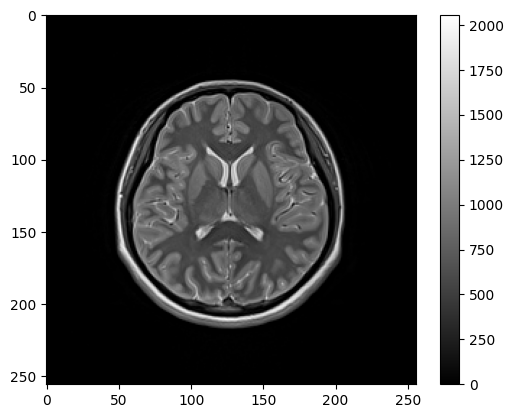

In [12]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

(256, 256, 32)


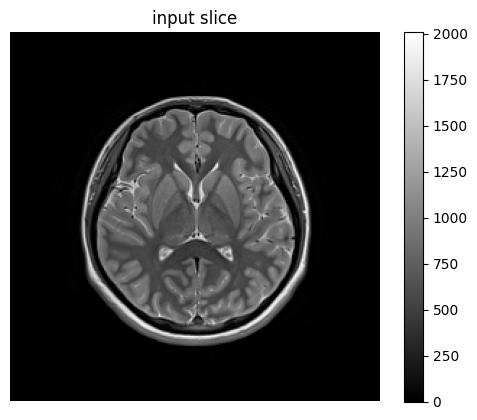

In [13]:
import numpy as np
import matplotlib.pyplot as plt

h = nib.load('/content/drive/MyDrive/DIP4E/s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

img = mri[:, :, mri.shape[2] // 2]    # 가운데 slice 한 장
img = np.rot90(img)                   # 보기 좋게 회전 (필요 없으면 지워도 됨)

plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title('input slice')
plt.colorbar()
plt.show()

이정도 알고리즘은 시험에 나올 수 있습니다.
파이썬 구현보다는 알고리즘은 제대로 할 줄 알아야 합니다.
코딩 하면 순서도 같은거 그리는데 그정도는 할 줄알아야 합니다.

iter 1: m1=295.52, m2=0.31, T=147.91, dT=146.91
iter 2: m1=780.15, m2=6.73, T=393.44, dT=245.52
iter 3: m1=810.69, m2=13.64, T=412.17, dT=18.73
iter 4: m1=813.67, m2=14.84, T=414.25, dT=2.09


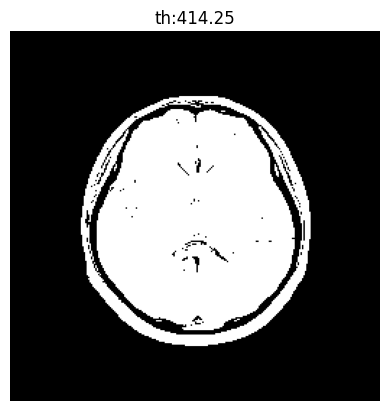

In [14]:
T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
while dT > esp:
    g1 = img[img > T[-1]]          # T보다 큰 픽셀 그룹
    g2 = img[img <= T[-1]]         # T 이하 픽셀 그룹
    m1 = g1.mean() if g1.size > 0 else 0   # g1의 평균 밝기
    m2 = g2.mean() if g2.size > 0 else 0   # g2의 평균 밝기
    T_new = 0.5 * (m1 + m2)        # 두 평균의 중간값을 새 임계값으로
    dT = abs(T_new - T[-1])        # 임계값 변화량
    T.append(T_new)
    print(f'iter {len(T)-1}: m1={m1:.2f}, m2={m2:.2f}, T={T_new:.2f}, dT={dT:.2f}')
##

bmsk = img > T[-1]
plt.imshow(bmsk, cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]:.2f}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

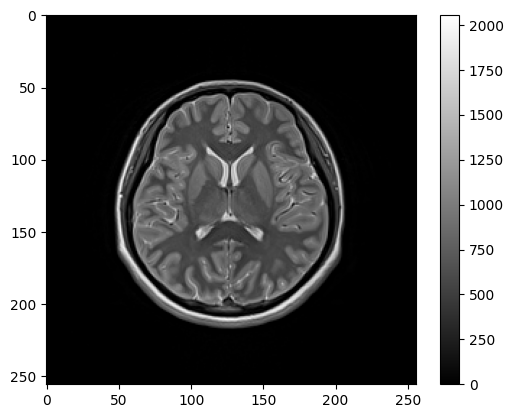

In [15]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

[ 64. 128.]
[  6.0276186  771.70171602]
[ 13.40759935 810.09474275]
[ 14.74370714 813.44144561]
final: [ 15.02870959 814.12189093]


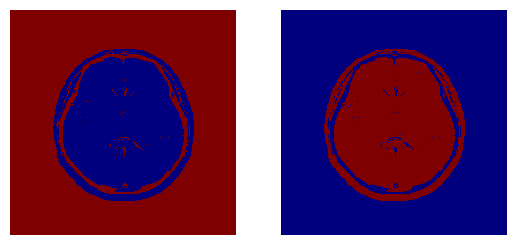

In [16]:
f = img.astype(float)                   # 앞에서 만든 MRI slice

m_vals = np.array([64., 128.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)
while E > eps:
    print(m_vals)

    ##
    # your k-means clustering algorithm #
    # 1) 각 픽셀과 각 cluster 평균(m_k) 사이의 거리
    for k in range(len(m_vals)):
        c[:, :, k] = np.abs(f - m_vals[k])
    # 2) 가장 가까운 cluster에 픽셀 할당
    cmap = np.argmin(c, axis=-1)
    # 3) cluster마다 새 평균 계산
    for k in range(len(m_vals)):
        if np.any(cmap == k):
            m_vals_new[k] = f[cmap == k].mean()
        else:
            m_vals_new[k] = m_vals[k]   # 빈 cluster는 평균 유지
    # 4) 평균이 얼마나 바뀌었는지 → 작으면 종료
    E = np.sum(np.abs(m_vals_new - m_vals))
    m_vals = m_vals_new.copy()
    ##

print('final:', m_vals)

for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals), i + 1)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.axis('off')
plt.show()

### k = 3 에서의 결과

[ 502.25 1004.5  1506.75]
[ 111.0913071   917.19478738 1545.48578982]
[  31.10296118  778.44216129 1530.09222083]
[  14.29106472  740.25282912 1472.56979167]
[  12.78696999  729.45355035 1423.85886556]
[  12.62906956  724.16499391 1392.68110077]
[  12.51203807  720.96638999 1374.76290631]
[  12.41122271  718.56683518 1361.90124816]
[  12.3726171   717.25398136 1354.71259419]
[  12.32641027  716.19845071 1349.24753173]
[  12.32641027  715.5769641  1345.622168  ]
[  12.3187298   715.23763492 1343.77165627]
[  12.3187298   714.99477714 1342.36460849]
[  12.3187298   714.77098058 1341.07282721]
[  12.3187298   714.60345852 1340.10787671]
final: [  12.3187298   714.60345852 1340.10787671]


(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

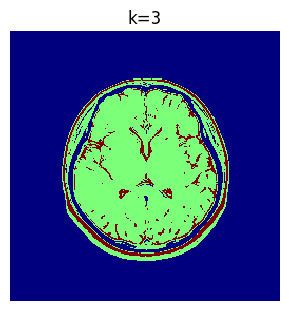

In [19]:
k = 3
m_vals = np.linspace(f.min(), f.max(), k + 2)[1:-1]   # 초기 평균 3개 (밝기 범위에 고르게)
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)
while E > eps:
    print(m_vals)

    ##
    for i in range(len(m_vals)):
        c[:, :, i] = np.abs(f - m_vals[i])        # 각 cluster 평균과의 거리
    cmap = np.argmin(c, axis=-1)                  # 가장 가까운 cluster에 할당
    for i in range(len(m_vals)):
        if np.any(cmap == i):
            m_vals_new[i] = f[cmap == i].mean()   # 새 평균
        else:
            m_vals_new[i] = m_vals[i]
    E = np.sum(np.abs(m_vals_new - m_vals))       # 평균 변화량
    m_vals = m_vals_new.copy()
    ##

print('final:', m_vals)

plt.figure(figsize=(16, 4))
plt.subplot(1, len(m_vals) + 1, 1)
plt.imshow(cmap, cmap='jet', interpolation='nearest')
plt.title('k=3')
plt.axis('off')

### k = 4 에서의 결과

[ 401.8  803.6 1205.4 1607.2]
[  66.91114622  800.53398675 1147.29904848 1643.60038241]
[  16.54068009  708.19758927 1111.90116703 1637.06697674]
[  12.25744867  670.27626786 1042.483084   1623.71189427]
[  11.37136725  638.22172231  990.7502097  1599.83212851]
[  10.69395369  613.32859386  957.02071669 1575.26559061]
[  10.32184135  595.63301887  934.30285499 1552.82237288]
[   9.98182938  584.18014269  920.97203129 1538.79198966]
[   9.86712148  578.30889999  913.19769585 1527.6677038 ]
[   9.79779436  574.9625868   908.67139453 1520.65227964]
[   9.77909127  573.05843544  906.20089888 1517.73871162]
[   9.73559524  572.21848739  905.11978933 1515.55409444]
[   9.72320937  571.54390218  904.40236686 1515.19044776]
[   9.72320937  571.08646021  903.81848552 1514.64481526]
final: [   9.72320937  571.08646021  903.81848552 1514.64481526]


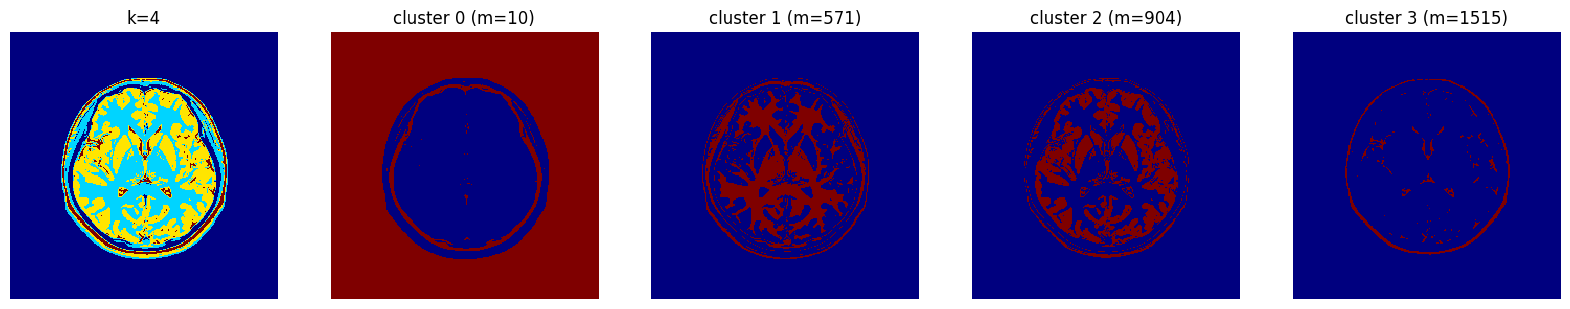

In [20]:
k = 4
m_vals = np.linspace(f.min(), f.max(), k + 2)[1:-1]   # 초기 평균 4개 (밝기 범위에 고르게)
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)
while E > eps:
    print(m_vals)

    ##
    for i in range(len(m_vals)):
        c[:, :, i] = np.abs(f - m_vals[i])        # 각 cluster 평균과의 거리
    cmap = np.argmin(c, axis=-1)                  # 가장 가까운 cluster에 할당
    for i in range(len(m_vals)):
        if np.any(cmap == i):
            m_vals_new[i] = f[cmap == i].mean()   # 새 평균
        else:
            m_vals_new[i] = m_vals[i]
    E = np.sum(np.abs(m_vals_new - m_vals))       # 평균 변화량
    m_vals = m_vals_new.copy()
    ##

print('final:', m_vals)

plt.figure(figsize=(20, 4))
plt.subplot(1, len(m_vals) + 1, 1)
plt.imshow(cmap, cmap='jet', interpolation='nearest')
plt.title('k=4')
plt.axis('off')
for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals) + 1, i + 2)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.title(f'cluster {i} (m={m_vals[i]:.0f})')
    plt.axis('off')
plt.show()